# 04 - Results analysis (Run 1)

Builds every table and figure for the Results chapter from files already committed
to the repository. **No GPU, no images, no network**: it reads only
`results/run1_cloud/metrics/*` and `results/run1_cloud/logs/*`, so anyone can rerun
it and obtain the same numbers.

| Output | Content | Source files |
|---|---|---|
| `results/tables/table_5_1_conditions.csv` | A-D summary, mean +/- SD over seeds | `{A_baseline_rerun,B_classical_rerun,C_gan,D_diffusion}_seed*.json` |
| `results/tables/table_5_2_per_class.csv` | Per-class recall, precision, specificity | same |
| `results/figures/fig08_per_class_recall.png` | Per-class recall by condition | same |
| `results/figures/fig09_paired_differences.png` | D23 paired comparison | `paired_comparison.csv` |
| `results/tables/table_5_3_fid.csv` | FID per class and pooled | `fid.csv` |
| `results/figures/fig10_audit_distances.png` | Nearest-neighbour distances vs threshold | `audit_*.csv` |
| `results/tables/table_5_4_audit.csv` | Near-duplicates and hubness | `audit_headline_summary.csv`, `audit_hubness.csv` |
| `results/figures/fig11_efficiency_curve.png` | Efficiency curve (D26) | `CURVE_*_seed*.json` |
| `results/figures/fig12_quantity_ablation.png` | Quantity ablation (D27) | `ABL_*_seed*.json`, `audit_df_ablation.csv` |
| `results/tables/table_5_5_cost.csv` | Training budget and sampling cost | `budget_state_*.json`, `sampling_*.json` |



In [1]:
import json, glob
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt

# Repository root, whether the notebook is run from notebooks/ or from the root
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
MET, LOG = ROOT / "results/run1_cloud/metrics", ROOT / "results/run1_cloud/logs"
FIG, TAB = ROOT / "results/figures", ROOT / "results/tables"
FIG.mkdir(parents=True, exist_ok=True); TAB.mkdir(parents=True, exist_ok=True)
assert MET.exists(), f"metrics folder not found: {MET}"

SEEDS = [42, 43, 44]
CLASSES = ["akiec", "bcc", "bkl", "df", "mel", "nv", "vasc"]
CONDS = {"A_baseline_rerun": "A baseline", "B_classical_rerun": "B classical",
         "C_gan": "C GAN", "D_diffusion": "D diffusion"}

# One colour per entity, used identically in every figure (fixed order, never by rank)
COL = {"A baseline": "#8a8985", "B classical": "#1baf7a", "C GAN": "#2a78d6", "D diffusion": "#eb6834",
       "gan": "#2a78d6", "lora": "#eb6834", "real": "#8a8985"}
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
ARM_NAME = {"gan": "GAN (WGAN-GP)", "lora": "Diffusion (LoRA)",
            "gan_final": "GAN (WGAN-GP)", "lora_final": "Diffusion (LoRA)"}

mpl.rcParams.update({
    "font.family": "serif", "font.serif": ["Times New Roman", "DejaVu Serif"],
    "font.size": 10, "axes.titlesize": 11, "axes.labelsize": 10,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "legend.frameon": False, "savefig.dpi": 300, "savefig.bbox": "tight", "figure.dpi": 110,
})

def save(fig, name):
    fig.savefig(FIG / f"{name}.png", facecolor="white")
    print(f"saved {FIG / (name + '.png')}")

def load(name):
    return json.loads((MET / f"{name}.json").read_text())

def ms(v, d=3):
    return f"{np.mean(v):.{d}f} ± {np.std(v, ddof=1):.{d}f}"

print("repository:", ROOT)

repository: d:\thesis


## 1. Conditions A-D (Table 5.1, Table 5.2, Figure 8)

In [2]:
RUNS = {lab: [load(f"{c}_seed{s}") for s in SEEDS] for c, lab in CONDS.items()}
METRICS = [("macro_f1", "Macro-F1 (primary)"), ("melanoma_recall", "Melanoma recall (primary)"),
           ("balanced_accuracy", "Balanced accuracy"), ("macro_auroc", "Macro AUROC"),
           ("macro_auprc", "Macro AUPRC (D23)"), ("macro_precision", "Macro precision (D23)"),
           ("accuracy", "Accuracy (reported only)")]
t51 = pd.DataFrame({lab: {name: ms([r[k] for r in rs]) for k, name in METRICS} for lab, rs in RUNS.items()})
t51.index.name = "metric"
t51.to_csv(TAB / "table_5_1_conditions.csv")
t51

,A baseline,B classical,C GAN,D diffusion
metric,,,,
Macro-F1 (primary),0.620 ± 0.048,0.663 ± 0.019,0.633 ± 0.013,0.636 ± 0.016
Melanoma recall (primary),0.469 ± 0.021,0.445 ± 0.023,0.493 ± 0.034,0.409 ± 0.009
Balanced accuracy,0.598 ± 0.045,0.661 ± 0.025,0.605 ± 0.015,0.610 ± 0.014
Macro AUROC,0.935 ± 0.004,0.948 ± 0.003,0.937 ± 0.004,0.939 ± 0.002
Macro AUPRC (D23),0.674 ± 0.024,0.707 ± 0.016,0.677 ± 0.007,0.694 ± 0.015
Macro precision (D23),0.661 ± 0.052,0.678 ± 0.013,0.679 ± 0.054,0.686 ± 0.029
Accuracy (reported only),0.796 ± 0.014,0.806 ± 0.004,0.801 ± 0.016,0.798 ± 0.005


In [3]:
rows = []
for lab, rs in RUNS.items():
    for c in CLASSES:
        pc = [r["per_class"][c] for r in rs]
        rows.append({"condition": lab, "class": c, "test_support": pc[0]["support"],
                     "recall": ms([p["recall"] for p in pc]), "precision": ms([p["precision"] for p in pc]),
                     "specificity": ms([p["specificity"] for p in pc])})
t52 = pd.DataFrame(rows)
t52.to_csv(TAB / "table_5_2_per_class.csv", index=False)
t52.pivot(index="class", columns="condition", values="recall")

condition,A baseline,B classical,C GAN,D diffusion
class,,,,
akiec,0.596 ± 0.084,0.538 ± 0.157,0.551 ± 0.059,0.487 ± 0.022
bcc,0.615 ± 0.035,0.662 ± 0.000,0.596 ± 0.072,0.573 ± 0.029
bkl,0.447 ± 0.052,0.535 ± 0.054,0.547 ± 0.038,0.503 ± 0.026
df,0.450 ± 0.173,0.683 ± 0.029,0.483 ± 0.104,0.667 ± 0.161
mel,0.469 ± 0.021,0.445 ± 0.023,0.493 ± 0.034,0.409 ± 0.009
nv,0.941 ± 0.012,0.937 ± 0.003,0.932 ± 0.021,0.948 ± 0.009
vasc,0.667 ± 0.082,0.825 ± 0.055,0.635 ± 0.073,0.683 ± 0.073


saved d:\thesis\results\figures\fig08_per_class_recall.png


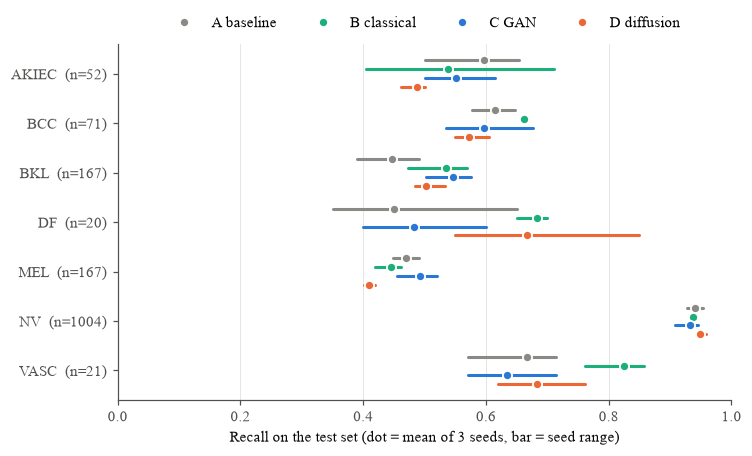

In [4]:
fig, ax = plt.subplots(figsize=(7.2, 4.2))
off = np.linspace(-0.27, 0.27, len(RUNS))
for k, (lab, rs) in enumerate(RUNS.items()):
    for i, c in enumerate(CLASSES):
        v = np.array([r["per_class"][c]["recall"] for r in rs])
        y = i + off[k]
        ax.plot([v.min(), v.max()], [y, y], color=COL[lab], lw=2, solid_capstyle="round")
        ax.plot(v.mean(), y, "o", ms=6, color=COL[lab], mec="white", mew=1.2,
                label=lab if i == 0 else None)
sup = {c: RUNS["A baseline"][0]["per_class"][c]["support"] for c in CLASSES}
ax.set_yticks(range(len(CLASSES)), [f"{c.upper()}  (n={sup[c]})" for c in CLASSES])
ax.invert_yaxis(); ax.set_xlim(0, 1); ax.grid(axis="y", visible=False)
ax.set_xlabel("Recall on the test set (dot = mean of 3 seeds, bar = seed range)")
ax.legend(ncol=4, loc="lower center", bbox_to_anchor=(0.5, 1.0))
save(fig, "fig08_per_class_recall")

## 2. Paired comparison, D23 (Figure 9)

saved d:\thesis\results\figures\fig09_paired_differences.png


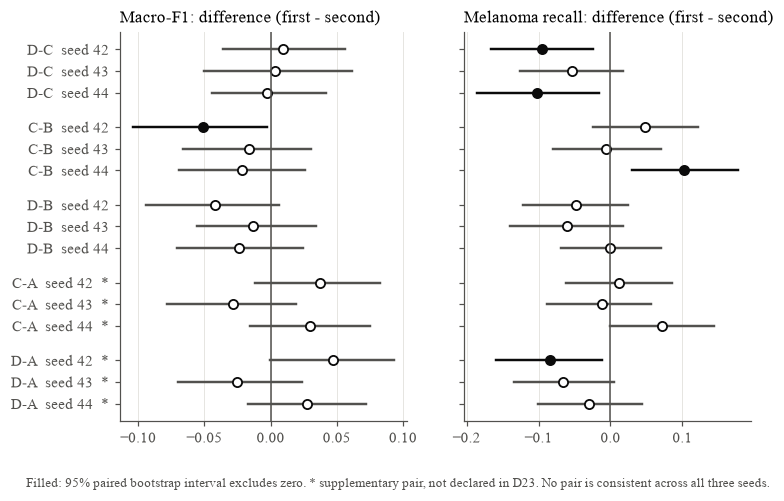

In [5]:
pc = pd.read_csv(MET / "paired_comparison.csv")
pairs = ["D-C", "C-B", "D-B", "C-A", "D-A"]
fig, axes = plt.subplots(1, 2, figsize=(7.4, 4.6), sharey=True)
for ax, (key, title) in zip(axes, [("macro_f1", "Macro-F1"), ("mel_recall", "Melanoma recall")]):
    labels, y = [], 0
    for p in pairs:
        for s in SEEDS:
            r = pc[(pc.pair == p) & (pc.seed == s)].iloc[0]
            lo, hi, d = r[f"{key}_lo"], r[f"{key}_hi"], r[f"{key}_diff"]
            excl = lo > 0 or hi < 0
            ax.plot([lo, hi], [y, y], color=INK if excl else MUTED, lw=1.6)
            ax.plot(d, y, "o", ms=6, mfc=INK if excl else "white", mec=INK, mew=1.2)
            labels.append(f"{p}  seed {s}" + ("" if r["status"] == "declared" else "  *")); y += 1
        y += 0.6
    ax.axvline(0, color=MUTED, lw=1)
    ax.set_title(f"{title}: difference (first - second)", loc="left")
    ax.grid(axis="y", visible=False)
ticks = [i + 0.6 * (i // 3) for i in range(len(labels))]
axes[0].set_yticks(ticks, labels); axes[0].invert_yaxis()
fig.text(0.01, -0.02, "Filled: 95% paired bootstrap interval excludes zero. "
         "* supplementary pair, not declared in D23. No pair is consistent across all three seeds.",
         fontsize=8.5, color=MUTED)
save(fig, "fig09_paired_differences")

## 3. Image quality (Table 5.3)

In [6]:
fid = pd.read_csv(MET / "fid.csv")
t53 = fid.pivot(index="class", columns="arm", values="fid").rename(columns=ARM_NAME).round(1)
t53["real reference n"] = fid.groupby("class").n_real.first()
t53 = t53.loc[["akiec", "bcc", "df", "mel", "vasc", "ALL"]]
t53.to_csv(TAB / "table_5_3_fid.csv")
t53

arm,GAN (WGAN-GP),Diffusion (LoRA),real reference n
class,,,
akiec,256.0,169.7,222
bcc,227.7,149.0,361
df,280.6,204.9,71
mel,216.7,170.8,773
vasc,237.2,237.7,99
ALL,206.7,137.5,1526


## 4. Memorization audit (Figure 10, Table 5.4)

saved d:\thesis\results\figures\fig10_audit_distances.png
tau 0.1333; near-duplicates: GAN (WGAN-GP) 0, Diffusion (LoRA) 0


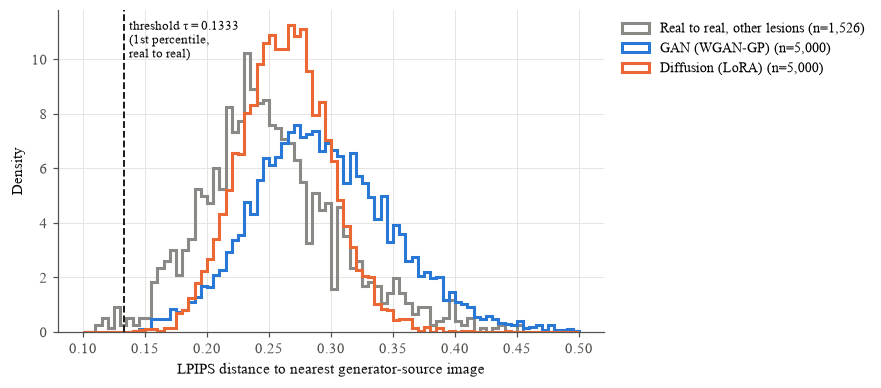

In [7]:
r2r = pd.read_csv(MET / "audit_real_to_real.csv")
head = pd.read_csv(MET / "audit_headline_per_image.csv")
tau = float(np.percentile(r2r.nn_dist, 1.0))
fig, ax = plt.subplots(figsize=(6.4, 3.8))
bins = np.linspace(0.10, 0.50, 81)
series = [("real", "Real to real, other lesions (n=1,526)", r2r.nn_dist)] + \
         [(a, f"{ARM_NAME[a]} (n={(head.arm == a).sum():,})", head[head.arm == a].nn_dist)
          for a in ["gan_final", "lora_final"]]
for key, lab, d in series:
    ax.hist(d, bins=bins, density=True, histtype="step", lw=2,
            color=COL["real" if key == "real" else key.split("_")[0]], label=lab)
ax.axvline(tau, color=INK, lw=1.2, ls="--")
ax.text(tau + 0.004, ax.get_ylim()[1] * 0.97, f"threshold τ = {tau:.4f}\n(1st percentile,\nreal to real)",
        va="top", ha="left", fontsize=8.5, color=INK)
ax.set_xlabel("LPIPS distance to nearest generator-source image")
ax.set_ylabel("Density"); ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0), fontsize=9)
save(fig, "fig10_audit_distances")
print(f"tau {tau:.4f}; near-duplicates: " +
      ", ".join(f"{ARM_NAME[a]} {(g.nn_dist < tau).sum()}" for a, g in head.groupby("arm")))

In [8]:
summ = pd.read_csv(MET / "audit_headline_summary.csv")
hub = pd.read_csv(MET / "audit_hubness.csv").set_index("arm")
t54 = summ[summ["class"] == "ALL"].set_index("arm")[["n", "near_duplicates", "min", "p01", "median"]]
t54 = t54.join(hub[["distinct_real_nn", "hub_share", "hub_class", "to_hub_df", "real_images_with_hub_as_nn",
                    "same_class_nn_share"]])
t54.index = [ARM_NAME[a] for a in t54.index]
t54.to_csv(TAB / "table_5_4_audit.csv")
t54.T

,GAN (WGAN-GP),Diffusion (LoRA)
n,5000,5000
near_duplicates,0,0
min,0.143906,0.143222
p01,0.171873,0.183955
median,0.289505,0.262826
distinct_real_nn,270,251
hub_share,0.3284,0.0712
hub_class,df,vasc
to_hub_df,696,177
real_images_with_hub_as_nn,2,2


## 5. Efficiency curve, D26 (Figure 11)

saved d:\thesis\results\figures\fig11_efficiency_curve.png


gan                           lora                
           macro_f1 melanoma_recall       macro_f1 melanoma_recall
1.0h  0.647 ± 0.012   0.483 ± 0.018  0.653 ± 0.017   0.499 ± 0.015
2.0h  0.644 ± 0.028   0.427 ± 0.021  0.630 ± 0.011   0.447 ± 0.087
3.0h  0.656 ± 0.011   0.399 ± 0.054  0.632 ± 0.011   0.465 ± 0.105
4.0h  0.623 ± 0.008   0.469 ± 0.028  0.659 ± 0.019   0.453 ± 0.112

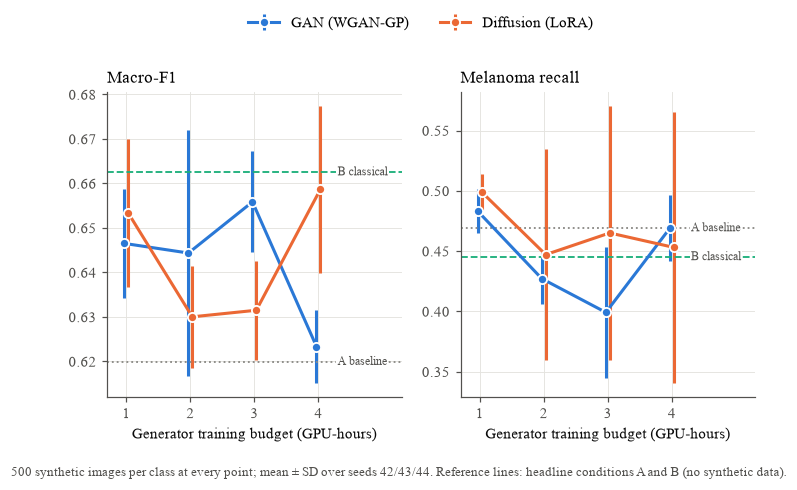

In [9]:
LABS = ["1.0h", "2.0h", "3.0h", "4.0h"]
curve = {(arm, lab): [load(f"CURVE_{arm}_{lab}_seed{s}") for s in SEEDS] for arm in ["gan", "lora"] for lab in LABS}
x = np.array([1.0, 2.0, 3.0, 4.0])
fig, axes = plt.subplots(1, 2, figsize=(7.6, 3.6))
for ax, (k, title) in zip(axes, [("macro_f1", "Macro-F1"), ("melanoma_recall", "Melanoma recall")]):
    for j, arm in enumerate(["gan", "lora"]):
        m = np.array([np.mean([r[k] for r in curve[(arm, l)]]) for l in LABS])
        s = np.array([np.std([r[k] for r in curve[(arm, l)]], ddof=1) for l in LABS])
        xx = x + (j - 0.5) * 0.06
        ax.errorbar(xx, m, yerr=s, color=COL[arm], lw=2, marker="o", ms=6, mec="white", mew=1.2,
                    capsize=0, label=ARM_NAME[arm])
    for lab_, ls in [("A baseline", ":"), ("B classical", "--")]:
        ref = np.mean([r[k] for r in RUNS[lab_]])
        ax.axhline(ref, color=COL[lab_], lw=1.2, ls=ls)
        ax.text(4.3, ref, lab_, va="center", fontsize=8, color=MUTED,
                bbox=dict(fc="white", ec="none", pad=1))
    ax.set_xticks(x, ["1", "2", "3", "4"]); ax.set_xlim(0.7, 5.3)
    ax.set_xlabel("Generator training budget (GPU-hours)"); ax.set_title(title, loc="left")
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, ncol=2, loc="lower center", bbox_to_anchor=(0.5, 1.0))
fig.text(0.01, -0.09, "500 synthetic images per class at every point; mean ± SD over seeds 42/43/44. "
         "Reference lines: headline conditions A and B (no synthetic data).", fontsize=8.5, color=MUTED)
save(fig, "fig11_efficiency_curve")
pd.DataFrame({(arm, k): [ms([r[k] for r in curve[(arm, l)]]) for l in LABS]
              for arm in ["gan", "lora"] for k in ["macro_f1", "melanoma_recall"]}, index=LABS)

## 6. Quantity ablation, D27 (Figure 12)

saved d:\thesis\results\figures\fig12_quantity_ablation.png


,gan,lora,gan,lora,gan,lora
,df_recall,df_recall,df_precision,df_precision,macro_f1,macro_f1
0,0.450 ± 0.173,0.450 ± 0.173,0.518 ± 0.115,0.518 ± 0.115,0.620 ± 0.048,0.620 ± 0.048
100,0.583 ± 0.076,0.517 ± 0.231,0.550 ± 0.098,0.568 ± 0.110,0.668 ± 0.010,0.654 ± 0.036
250,0.483 ± 0.225,0.583 ± 0.029,0.437 ± 0.092,0.498 ± 0.066,0.618 ± 0.043,0.632 ± 0.011
500,0.483 ± 0.161,0.650 ± 0.087,0.508 ± 0.034,0.486 ± 0.085,0.627 ± 0.010,0.649 ± 0.021
1000,0.483 ± 0.247,0.533 ± 0.161,0.470 ± 0.091,0.529 ± 0.109,0.634 ± 0.042,0.665 ± 0.037
2000,0.300 ± 0.100,0.533 ± 0.104,0.554 ± 0.058,0.655 ± 0.109,0.623 ± 0.018,0.668 ± 0.027


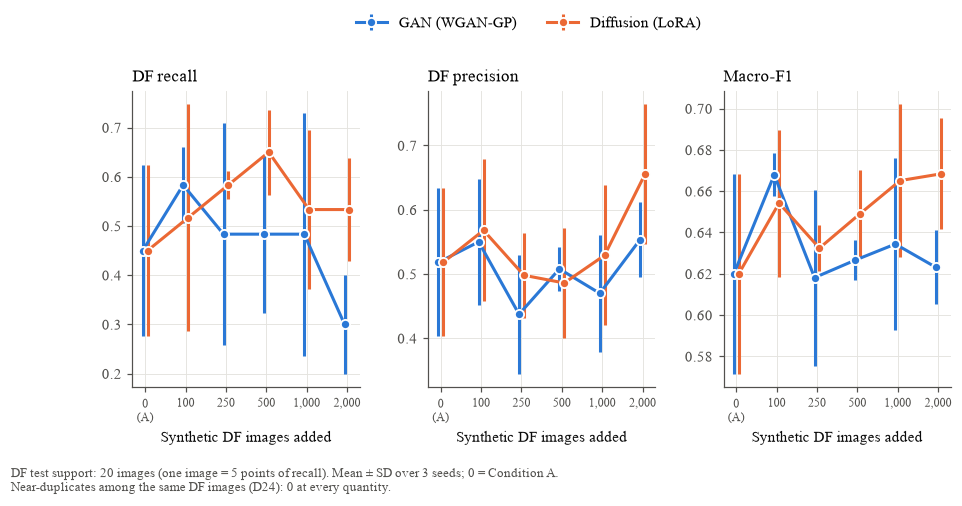

In [10]:
QTY = [0, 100, 250, 500, 1000, 2000]
abl_audit = pd.read_csv(MET / "audit_df_ablation.csv")
def runs_at(arm, n):
    return RUNS["A baseline"] if n == 0 else [load(f"ABL_{arm}_df{n}_seed{s}") for s in SEEDS]
get = {"df_recall": lambda r: r["per_class"]["df"]["recall"],
       "df_precision": lambda r: r["per_class"]["df"]["precision"],
       "macro_f1": lambda r: r["macro_f1"]}
fig, axes = plt.subplots(1, 3, figsize=(9.6, 3.5))
fig.subplots_adjust(wspace=0.3)
pos = np.arange(len(QTY))
table = {}
for ax, (k, title) in zip(axes, [("df_recall", "DF recall"), ("df_precision", "DF precision"), ("macro_f1", "Macro-F1")]):
    for j, arm in enumerate(["gan", "lora"]):
        vals = [[get[k](r) for r in runs_at(arm, n)] for n in QTY]
        m, s = np.array([np.mean(v) for v in vals]), np.array([np.std(v, ddof=1) for v in vals])
        ax.errorbar(pos + (j - 0.5) * 0.12, m, yerr=s, color=COL[arm], lw=2, marker="o", ms=6,
                    mec="white", mew=1.2, capsize=0, label=ARM_NAME[arm])
        table[(arm, k)] = [ms(v) for v in vals]
    ax.set_xticks(pos, ["0\n(A)", "100", "250", "500", "1,000", "2,000"], fontsize=8)
    ax.set_xlabel("Synthetic DF images added"); ax.set_title(title, loc="left")
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, ncol=2, loc="lower center", bbox_to_anchor=(0.5, 1.0))
nd = int(abl_audit.near_duplicates.sum())
fig.text(0.01, -0.16, f"DF test support: 20 images (one image = 5 points of recall). Mean ± SD over 3 seeds; "
         f"0 = Condition A.\nNear-duplicates among the same DF images (D24): {nd} at every quantity.",
         fontsize=8.5, color=MUTED)
save(fig, "fig12_quantity_ablation")
pd.DataFrame(table, index=QTY)

## 7. Training budget and sampling cost (Table 5.5)

In [11]:
rows = []
for arm in ["gan", "diffusion"]:
    b = json.loads((LOG / f"budget_state_run1_cloud_{arm}.json").read_text())
    rows.append({"item": f"Training, {arm}", "gpu_hours": round(b["cumulative_gpu_hours"], 3),
                 "detail": f"{b['optimiser_steps']} steps, {len(b['segments'])} segment(s), "
                           f"{', '.join(sorted({s['device']['name'] for s in b['segments']}))}"})
for f in sorted(LOG.glob("sampling_*.json")):
    if "smoke" in f.name:
        continue
    j = json.loads(f.read_text())
    n = sum(s["images_generated_this_session"] for s in j["sessions"])
    rows.append({"item": f"Sampling, {f.stem.replace('sampling_', '')}", "gpu_hours": round(j["total_hours"], 3),
                 "detail": f"{n:,} images, {j['latest']['seconds_per_image']} s/image"})
t55 = pd.DataFrame(rows)
t55.to_csv(TAB / "table_5_5_cost.csv", index=False)
t55

,item,gpu_hours,detail
0,"Training, gan",4.001,"3943 steps, 1 segment(s), Tesla T4"
1,"Training, diffusion",4.001,"2741 steps, 1 segment(s), Tesla T4"
2,"Sampling, ablation_df_gan",0.002,"1,000 images, 0.006 s/image"
3,"Sampling, ablation_df_lora",1.566,"1,000 images, 5.637 s/image"
4,"Sampling, curve_gan_1.0h",0.004,"2,500 images, 0.006 s/image"
5,"Sampling, curve_gan_2.0h",0.004,"2,500 images, 0.006 s/image"
6,"Sampling, curve_gan_3.0h",0.005,"2,500 images, 0.007 s/image"
7,"Sampling, curve_gan_4.0h",0.004,"2,500 images, 0.006 s/image"
8,"Sampling, curve_lora_1.0h",3.801,"2,500 images, 5.473 s/image"
9,"Sampling, curve_lora_2.0h",3.801,"2,500 images, 5.473 s/image"


In [13]:
print("Tables:")
for p in sorted(TAB.glob("table_5_*.csv")): print("  ", p.name)
print("Figures:")
for p in sorted(FIG.glob("fig0[89]_*.png")) + sorted(FIG.glob("fig1[0-2]_*.png")): print("  ", p.name)

Tables:
   table_5_1_conditions.csv
   table_5_2_per_class.csv
   table_5_3_fid.csv
   table_5_4_audit.csv
   table_5_5_cost.csv
Figures:
   fig08_per_class_recall.png
   fig09_paired_differences.png
   fig10_audit_distances.png
   fig11_efficiency_curve.png
   fig12_quantity_ablation.png
